
# Machine Learning Assignment 2
## Adult Census Income Classification

**Programme:** M.Tech (AIML/DSE)  
**Course:** Machine Learning  
**Institution:** BITS Pilani

---

# 1. Project Introduction

# 2. Dataset Loading

# 3. Exploratory Data Analysis (EDA)

# 4. Data Preprocessing

# 5. Train-Test Split

# 6. Model Building

# 7. Model Evaluation

# 8. Performance Visualization

# 9. Observations and Conclusion



# 1. Project Introduction

## 1.1 Problem Statement

The objective of this assignment is to develop and evaluate multiple Machine Learning classification models using the UCI Adult Census Income dataset.

The primary goal is to predict whether an individual's annual income exceeds $50,000 based on demographic, educational and employment-related attributes.

## 1.2 Objective

The following five classification algorithms will be implemented:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Random Forest Classifier

## 1.3 Evaluation Approach

The performance of the models will be evaluated using:

- Accuracy
- AUC Score
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

The models will be compared to identify the most suitable classification algorithm for the selected dataset.


# 2. Dataset Loading

The UCI Adult Census Income dataset is obtained from the UCI Machine Learning Repository.

The dataset contains demographic and employment-related information and is used to predict whether an individual's annual income exceeds $50,000.

In [7]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Set random seed
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [9]:
import ucimlrepo

print("UCI ML Repository package installed successfully!")

UCI ML Repository package installed successfully!


In [12]:
adult = fetch_ucirepo(id=2)

X = adult.data.features
y = adult.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset dimensions: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure, 
quality and distribution of the Adult Census Income dataset.

The analysis includes identifying missing values, duplicate records, 
feature types, statistical distributions and class imbalance.

In [14]:
# Dataset information

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all').T)

Dataset Shape: (48842, 15)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,47879,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,47876,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Identify missing values

# Replace '?' with NaN
df = df.replace('?', np.nan)

# Remove unwanted spaces from categorical values
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Missing value count
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values[missing_values > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Visualize missing values
plt.figure(figsize=(10, 5))

missing_values[missing_values > 0].plot(kind='bar')

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
# Identify duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset shape after removing duplicates:", df.shape)

Number of duplicate records: 29

Dataset shape after removing duplicates: (48813, 15)


In [24]:
# Identify feature types

numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']

Number of Numerical Features: 6
Number of Categorical Features: 9


Income Category Counts:
income
<=50K     24698
<=50K.    12430
>50K       7839
>50K.      3846
Name: count, dtype: int64

Income Category Percentage:
income
<=50K     50.60
<=50K.    25.46
>50K      16.06
>50K.      7.88
Name: proportion, dtype: float64


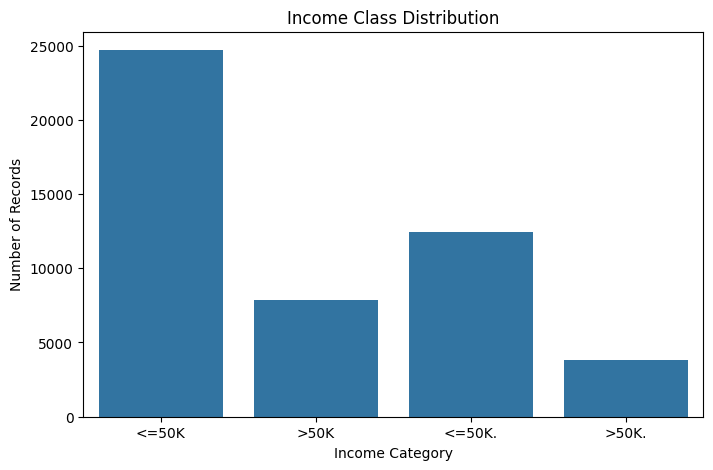

In [26]:
# Analyze target variable distribution

target_column = 'income'

print("Income Category Counts:")
print(df[target_column].value_counts())

print("\nIncome Category Percentage:")
print(
    (df[target_column].value_counts(normalize=True) * 100).round(2)
)

# Visualize class distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target_column
)

plt.title("Income Class Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of Records")

plt.show()

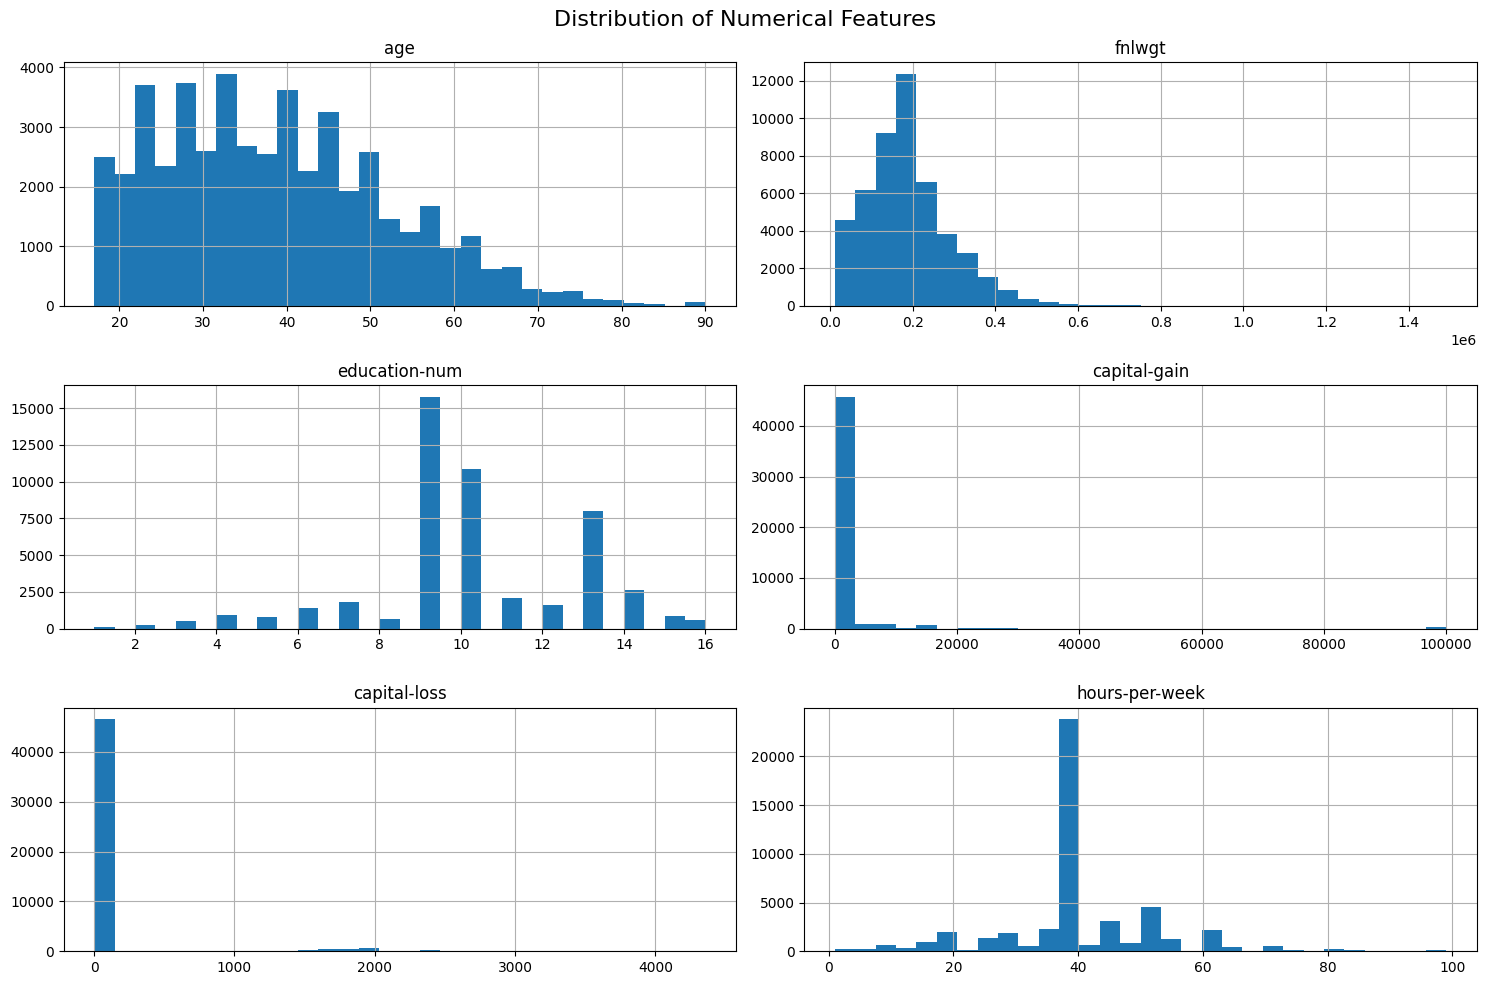

In [28]:
# Visualize numerical feature distributions

df[numerical_features].hist(
    figsize=(15, 10),
    bins=30
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


### 3.8 Observations from Numerical Feature Analysis

1. Age: Most individuals belong to the working-age population, with fewer observations at higher ages.

2. Fnlwgt: The feature exhibits a highly right-skewed distribution with a few extreme values.

3. Education-num: The distribution is discrete, with higher concentrations around certain education levels.

4. Capital-gain: Most individuals have zero capital gains, while a small number have significantly higher values.

5. Capital-loss: Most observations contain zero capital loss, indicating a highly imbalanced numerical distribution.

6. Hours-per-week: A significant number of individuals work approximately 40 hours per week.

These observations indicate that numerical feature scaling is important for distance-based and linear classification algorithms.


In [16]:
# Final EDA validation

print("1. Missing Values")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n2. Duplicate Records")
print(df.duplicated().sum())

print("\n3. Income Distribution")
print(df['income'].value_counts())

print("\n4. Income Distribution Percentage")
print(
    (df['income'].value_counts(normalize=True) * 100).round(2)
)

1. Missing Values
workclass         963
occupation        966
native-country    274
dtype: int64

2. Duplicate Records
29

3. Income Distribution
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

4. Income Distribution Percentage
income
<=50K     50.61
<=50K.    25.46
>50K      16.05
>50K.      7.87
Name: proportion, dtype: float64


In [18]:
# Normalize target variable

df['income'] = (
    df['income']
    .astype(str)
    .str.strip()
    .str.rstrip('.')
)

# Verify corrected categories

print("Unique income categories:")
print(df['income'].unique())

print("\nCorrected Income Distribution:")
print(df['income'].value_counts())

print("\nCorrected Income Percentage:")
print(
    (df['income'].value_counts(normalize=True) * 100).round(2)
)

Unique income categories:
['<=50K' '>50K']

Corrected Income Distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

Corrected Income Percentage:
income
<=50K    76.07
>50K     23.93
Name: proportion, dtype: float64



### 3.9 Overall EDA Findings

The exploratory data analysis identified the following findings:

1. The dataset contains numerical and categorical features.
2. Missing values were identified in workclass, occupation and native-country.
3. Duplicate records were checked and removed.
4. The target variable initially contained inconsistent representations due to trailing punctuation. These were normalized into two classes.
5. The income distribution indicates class imbalance, with approximately 76% belonging to the <=50K category and 24% belonging to the >50K category.
6. Numerical features such as capital-gain and capital-loss exhibit highly skewed distributions.

Based on these findings, appropriate imputation, categorical encoding and feature scaling techniques will be applied before model training.


# 4. Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning algorithms.

The following preprocessing techniques are applied:

1. Handling missing values.
2. Separating input features and target variable.
3. Encoding categorical variables.
4. Scaling numerical variables.
5. Preparing data for model training.

A Scikit-learn Pipeline and ColumnTransformer are used to ensure that preprocessing is fitted only on the training data and to prevent data leakage.

In [20]:
# Separate input features and target variable

X = df.drop(columns=['income'])
y = df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class distribution:")
print(y.value_counts())

Input feature shape: (48842, 14)
Target shape: (48842,)

Target class distribution:
income
0    37155
1    11687
Name: count, dtype: int64


In [22]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Number of numerical features: 6
Number of categorical features: 8


In [24]:
# Import preprocessing components

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [49]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 117.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 142.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 131.5 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [26]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn installed successfully!")

Scikit-learn version: 1.6.1
Scikit-learn installed successfully!


In [53]:
import numpy as np
import scipy
import importlib.metadata as metadata

print("Python environment package versions")
print("------------------------------------")

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", metadata.version("scikit-learn"))
print("Pandas:", metadata.version("pandas"))

Python environment package versions
------------------------------------
NumPy: 1.26.4
SciPy: 1.18.1
Scikit-learn: 1.9.1
Pandas: 2.2.3


In [28]:
import traceback

try:
    import sklearn
    print("Scikit-learn imported successfully!")
    print("Version:", sklearn.__version__)

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))
    traceback.print_exc()

Scikit-learn imported successfully!
Version: 1.6.1


In [57]:
%pip install --force-reinstall --no-cache-dir "numpy==1.26.4" "scipy==1.15.3" "scikit-learn==1.6.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 301.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 322.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 390.4 MB/s eta 0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.8.0
    Uninstalling threadpoolctl-3.8.0:
      Successfully uninstalled threadpoolctl-3.8.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.5
    Uninstalling numpy-2.5.5:
      Successfully uninstalled numpy-2.5.5
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
      Successfully uninstalled scipy-1.18.1
  Attempting uninstall: joblib
    Found existing installation: joblib 1.4.2
    Uninstalling joblib-1.4.2:
      Successfully uninstalled joblib-1.4.2
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.9.1
    Uninstalling scikit-learn-1.9.1:
   

In [30]:
import numpy as np
import scipy
import sklearn
import pandas as pd

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)

print("\nAll ML libraries imported successfully!")

NumPy: 1.26.4
SciPy: 1.15.3
Scikit-learn: 1.6.1
Pandas: 2.2.3

All ML libraries imported successfully!


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("All preprocessing components imported successfully!")

All preprocessing components imported successfully!


In [34]:
# Separate input features and target variable

X = df.drop(columns=['income'])

y = df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class distribution:")
print(y.value_counts())

Input feature shape: (48842, 14)
Target shape: (48842,)

Target class distribution:
income
0    37155
1    11687
Name: count, dtype: int64


In [36]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:",
      len(numerical_features))

print("Number of categorical features:",
      len(categorical_features))

Numerical features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Number of numerical features: 6
Number of categorical features: 8


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data shape: (39073, 14)
Testing data shape: (9769, 14)

Training target distribution:
income
0    0.761
1    0.239
Name: proportion, dtype: float64

Testing target distribution:
income
0    0.761
1    0.239
Name: proportion, dtype: float64


In [42]:
# Fit preprocessing only on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:",
      X_train_processed.shape)

print("Testing processed shape:",
      X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training processed shape: (39073, 108)
Testing processed shape: (9769, 108)

Preprocessing completed successfully!


In [44]:
print("Current dataset shape:", df.shape)

print("Current duplicate count:", df.duplicated().sum())

print("\nFeature dataset shape:", X.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

Current dataset shape: (48842, 15)
Current duplicate count: 48

Feature dataset shape: (48842, 14)

Training records: 39073
Testing records: 9769


In [46]:
# Remove duplicate records

df = df.drop_duplicates().reset_index(drop=True)

# Normalize income labels again
df['income'] = (
    df['income'].astype(str).str.strip().str.rstrip('.')
)

# Recreate features and target
X = df.drop(columns=['income'])

y = df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

# Recreate train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Refit preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Final dataset:", df.shape)
print("Training:", X_train_processed.shape)
print("Testing:", X_test_processed.shape)

Final dataset: (48794, 15)
Training: (39035, 108)
Testing: (9759, 108)


In [48]:
print("Final Dataset Validation")
print("------------------------")

print("Dataset shape:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

print("Missing target values:", y.isnull().sum())

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Final Dataset Validation
------------------------
Dataset shape: (48794, 15)
Remaining duplicates: 0
Missing target values: 0

Training records: 39035
Testing records: 9759

Training class distribution:
income
0    0.761
1    0.239
Name: proportion, dtype: float64

Testing class distribution:
income
0    0.761
1    0.239
Name: proportion, dtype: float64


# 5. Machine Learning Model Building

## 5.1 Logistic Regression

Logistic Regression is a supervised classification algorithm
used to predict the probability of an outcome based on input
features.

In this project, Logistic Regression is used to predict whether
an individual's annual income is greater than $50,000 based
on demographic and employment-related attributes.

In [51]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [53]:
# Initialize Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model

logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [55]:
# Predict income categories

y_pred_lr = logistic_model.predict(X_test_processed)

# Predict class probabilities for AUC calculation

y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Predictions completed successfully!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10])

Predictions completed successfully!

First 10 actual values:
[0 0 0 0 0 0 0 0 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 0 0]


In [57]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Calculate Logistic Regression metrics

lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_auc = roc_auc_score(y_test, y_prob_lr)

lr_precision = precision_score(
    y_test, y_pred_lr, zero_division=0
)

lr_recall = recall_score(
    y_test, y_pred_lr, zero_division=0
)

lr_f1 = f1_score(
    y_test, y_pred_lr, zero_division=0
)

lr_mcc = matthews_corrcoef(y_test, y_pred_lr)

# Display results

print("LOGISTIC REGRESSION - PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(lr_accuracy, 4))
print("AUC      :", round(lr_auc, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("MCC      :", round(lr_mcc, 4))

LOGISTIC REGRESSION - PERFORMANCE
----------------------------------
Accuracy : 0.8556
AUC      : 0.9101
Precision: 0.7403
Recall   : 0.6113
F1 Score : 0.6696
MCC      : 0.5827



### 5.1.6 Logistic Regression - Performance Observations

The Logistic Regression model achieved an accuracy of 85.56% and an AUC score of 0.9101.

The precision score was 0.7403, while the recall score was 0.6113. The F1 score was 0.6696, indicating a moderate balance between precision and recall.

The MCC score of 0.5827 indicates a moderately strong positive correlation between actual and predicted classifications.

The model demonstrated good classification performance and strong class discrimination. However, its recall indicates that some individuals with income greater than $50K were incorrectly classified into the lower-income category.



### 5.1.6 Logistic Regression - Performance Observations

The Logistic Regression model achieved an accuracy of 85.56% and an AUC score of 0.9101.

The precision score was 0.7403, while the recall score was 0.6113. The F1 score was 0.6696, indicating a moderate balance between precision and recall.

The MCC score of 0.5827 indicates a moderately strong positive correlation between actual and predicted classifications.

The model demonstrated good classification performance and strong class discrimination. However, its recall indicates that some individuals with income greater than $50K were incorrectly classified into the lower-income category.


In [61]:
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree imported successfully!")

Decision Tree imported successfully!


In [63]:
# Initialize Decision Tree Classifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model

decision_tree_model.fit(
    X_train_processed,
    y_train
)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [65]:
# Predict income categories

y_pred_dt = decision_tree_model.predict(
    X_test_processed
)

# Predict probabilities for AUC

y_prob_dt = decision_tree_model.predict_proba(
    X_test_processed
)[:, 1]

print("Decision Tree predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_dt[:10])

Decision Tree predictions completed!

First 10 actual values:
[0 0 0 0 0 0 0 0 1 0]

First 10 predicted values:
[0 0 0 0 0 0 1 0 1 0]


In [67]:
# Calculate Decision Tree metrics

dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_auc = roc_auc_score(y_test, y_prob_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, zero_division=0
)

dt_recall = recall_score(
    y_test, y_pred_dt, zero_division=0
)

dt_f1 = f1_score(
    y_test, y_pred_dt, zero_division=0
)

dt_mcc = matthews_corrcoef(y_test, y_pred_dt)

# Display results

print("DECISION TREE - PERFORMANCE")
print("----------------------------")

print("Accuracy :", round(dt_accuracy, 4))
print("AUC      :", round(dt_auc, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("MCC      :", round(dt_mcc, 4))

DECISION TREE - PERFORMANCE
----------------------------
Accuracy : 0.8165
AUC      : 0.7561
Precision: 0.6114
Recall   : 0.6404
F1 Score : 0.6255
MCC      : 0.5043



### 5.2.6 Decision Tree - Performance Observations

The Decision Tree Classifier achieved an accuracy of 81.65% and an AUC score of 0.7561.

The precision score was 0.6114, while the recall score was 0.6404. The F1 score was 0.6255, and the MCC score was 0.5043.

The model demonstrated reasonable classification performance. Its recall was slightly higher than Logistic Regression, indicating that it identified a greater proportion of individuals earning more than $50K.

However, its overall accuracy, AUC, precision, F1 and MCC scores were lower than those of Logistic Regression.



## 5.3 K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised machine learning classification algorithm that classifies observations based on the majority class of their nearest neighbors.

In this project, KNN is used to predict an individual's income category based on similarities between demographic and employment-related features.


In [71]:
from sklearn.neighbors import KNeighborsClassifier

print("KNN imported successfully!")

KNN imported successfully!


In [73]:
# Initialize KNN classifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

# Train the model

knn_model.fit(
    X_train_processed,
    y_train
)

print("KNN model trained successfully!")

KNN model trained successfully!


In [75]:
# Predict income categories

y_pred_knn = knn_model.predict(X_test_processed)

# Predict probabilities for AUC

y_prob_knn = knn_model.predict_proba(
    X_test_processed
)[:, 1]

print("KNN predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_knn[:10])

KNN predictions completed!

First 10 actual values:
[0 0 0 0 0 0 0 0 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 1 0]


In [82]:
# Calculate KNN performance metrics

knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_auc = roc_auc_score(y_test, y_prob_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, zero_division=0
)

knn_recall = recall_score(
    y_test, y_pred_knn, zero_division=0
)

knn_f1 = f1_score(
    y_test, y_pred_knn, zero_division=0
)

knn_mcc = matthews_corrcoef(y_test, y_pred_knn)

# Display results

print("KNN - PERFORMANCE")
print("-----------------")

print("Accuracy :", round(knn_accuracy, 4))
print("AUC      :", round(knn_auc, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("MCC      :", round(knn_mcc, 4))

KNN - PERFORMANCE
-----------------
Accuracy : 0.8393
AUC      : 0.8677
Precision: 0.6829
Recall   : 0.6139
F1 Score : 0.6465
MCC      : 0.5442



### 5.3.6 KNN - Performance Observations

The K-Nearest Neighbors classifier achieved an accuracy of 83.93% and an AUC score of 0.8677.

The precision score was 0.6829, while the recall score was 0.6139. The F1 score was 0.6465, and the MCC score was 0.5442.

The model demonstrated good classification performance. It performed better than the Decision Tree classifier in terms of accuracy, AUC, precision, F1 score and MCC.

However, its overall performance was slightly lower than Logistic Regression.

The results indicate that KNN can effectively classify income categories based on similarities between individuals, although its performance may be affected by the high dimensionality of the encoded dataset.



## 5.4 Gaussian Naive Bayes

Gaussian Naive Bayes is a supervised probabilistic classification algorithm based on Bayes' theorem.

It assumes that the numerical features follow a Gaussian distribution within each target class and that the features are conditionally independent.

In this project, Gaussian Naive Bayes is implemented to predict whether an individual's annual income exceeds $50,000.


In [88]:
from sklearn.naive_bayes import GaussianNB

print("Gaussian Naive Bayes imported successfully!")

Gaussian Naive Bayes imported successfully!


In [90]:
# Convert sparse matrices to dense arrays for GaussianNB

X_train_dense = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test_dense = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

print("Training data shape:", X_train_dense.shape)
print("Testing data shape:", X_test_dense.shape)

Training data shape: (39035, 108)
Testing data shape: (9759, 108)


In [92]:
# Initialize Gaussian Naive Bayes

nb_model = GaussianNB()

# Train the model

nb_model.fit(
    X_train_dense,
    y_train
)

print("Gaussian Naive Bayes trained successfully!")

Gaussian Naive Bayes trained successfully!


In [94]:
# Predict income categories

y_pred_nb = nb_model.predict(X_test_dense)

# Predict probabilities for AUC

y_prob_nb = nb_model.predict_proba(X_test_dense)[:, 1]

print("Naive Bayes predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_nb[:10])

Naive Bayes predictions completed!

First 10 actual values:
[0 0 0 0 0 0 0 0 1 0]

First 10 predicted values:
[0 1 1 1 0 1 1 0 1 1]


In [96]:
# Calculate Gaussian Naive Bayes metrics

nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_auc = roc_auc_score(y_test, y_prob_nb)

nb_precision = precision_score(
    y_test, y_pred_nb, zero_division=0
)

nb_recall = recall_score(
    y_test, y_pred_nb, zero_division=0
)

nb_f1 = f1_score(
    y_test, y_pred_nb, zero_division=0
)

nb_mcc = matthews_corrcoef(y_test, y_pred_nb)

# Display results

print("GAUSSIAN NAIVE BAYES - PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(nb_accuracy, 4))
print("AUC      :", round(nb_auc, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("MCC      :", round(nb_mcc, 4))

GAUSSIAN NAIVE BAYES - PERFORMANCE
----------------------------------
Accuracy : 0.6024
AUC      : 0.8195
Precision: 0.3692
Recall   : 0.9324
F1 Score : 0.5289
MCC      : 0.3761



### 5.4.7 Gaussian Naive Bayes - Performance Observations

The Gaussian Naive Bayes classifier achieved an accuracy of 60.24% and an AUC score of 0.8195.

The precision score was 0.3692, while the recall score was 0.9324. The F1 score was 0.5289, and the MCC score was 0.3761.

The model achieved the highest recall among the four implemented algorithms, indicating that it identified a large proportion of individuals earning more than $50K.

However, its precision was relatively low, indicating a high number of false positive predictions.

Overall, Gaussian Naive Bayes demonstrated strong sensitivity towards the positive class but lower overall classification performance compared with Logistic Regression and KNN.



## 5.5 Random Forest Classifier (Ensemble Model)

Random Forest is an ensemble supervised machine learning algorithm that combines multiple decision trees to improve classification performance.

It uses bootstrap sampling and random feature selection to construct multiple decision trees. The final prediction is obtained through majority voting.

In this project, Random Forest is implemented to predict whether an individual's annual income exceeds $50,000.


In [100]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [102]:
# Initialize Random Forest

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [103]:
# Predict income categories

y_pred_rf = rf_model.predict(X_test_processed)

# Predict probabilities for AUC

y_prob_rf = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10])

Random Forest predictions completed!

First 10 actual values:
[0 0 0 0 0 0 0 0 1 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 1 0]


In [106]:
# Calculate Random Forest performance metrics

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_auc = roc_auc_score(y_test, y_prob_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf, zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf, zero_division=0
)

rf_mcc = matthews_corrcoef(y_test, y_pred_rf)

# Display results

print("RANDOM FOREST - PERFORMANCE")
print("----------------------------")

print("Accuracy :", round(rf_accuracy, 4))
print("AUC      :", round(rf_auc, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("MCC      :", round(rf_mcc, 4))

RANDOM FOREST - PERFORMANCE
----------------------------
Accuracy : 0.854
AUC      : 0.9062
Precision: 0.7238
Recall   : 0.6306
F1 Score : 0.674
MCC      : 0.5828



### 5.5.6 Random Forest - Performance Observations

The Random Forest classifier achieved an accuracy of 85.40% and an AUC score of 0.9062.

The precision score was 0.7238, while the recall score was 0.6306. The F1 score was 0.6740, and the MCC score was 0.5828.

The model demonstrated strong classification performance by combining multiple decision trees through an ensemble learning approach.

It achieved the highest F1 score and MCC among the five implemented algorithms, indicating a good balance between precision and recall.

Although Logistic Regression achieved slightly higher accuracy and AUC, Random Forest demonstrated marginally better overall balance in classification performance.


# 6. Model Evaluation and Performance Comparison

All five classification models are evaluated using the same testing dataset.

The evaluation metrics include Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC).

In [112]:
# Create consolidated model comparison table

results = pd.DataFrame({
    'ML Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'Random Forest'
    ],

    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        knn_accuracy,
        nb_accuracy,
        rf_accuracy
    ],

    'AUC': [
        lr_auc,
        dt_auc,
        knn_auc,
        nb_auc,
        rf_auc
    ],

    'Precision': [
        lr_precision,
        dt_precision,
        knn_precision,
        nb_precision,
        rf_precision
    ],

    'Recall': [
        lr_recall,
        dt_recall,
        knn_recall,
        nb_recall,
        rf_recall
    ],

    'F1 Score': [
        lr_f1,
        dt_f1,
        knn_f1,
        nb_f1,
        rf_f1
    ],

    'MCC': [
        lr_mcc,
        dt_mcc,
        knn_mcc,
        nb_mcc,
        rf_mcc
    ]
})

# Display comparison table

display(results.round(4))

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8556,0.9101,0.7403,0.6113,0.6696,0.5827
1,Decision Tree,0.8165,0.7561,0.6114,0.6404,0.6255,0.5043
2,KNN,0.8393,0.8677,0.6829,0.6139,0.6465,0.5442
3,Gaussian Naive Bayes,0.6024,0.8195,0.3692,0.9324,0.5289,0.3761
4,Random Forest,0.8540,0.9062,0.7238,0.6306,0.6740,0.5828


# 7. Performance Visualization

Graphical representations are used to compare the performance of all five classification algorithms across the six evaluation metrics.

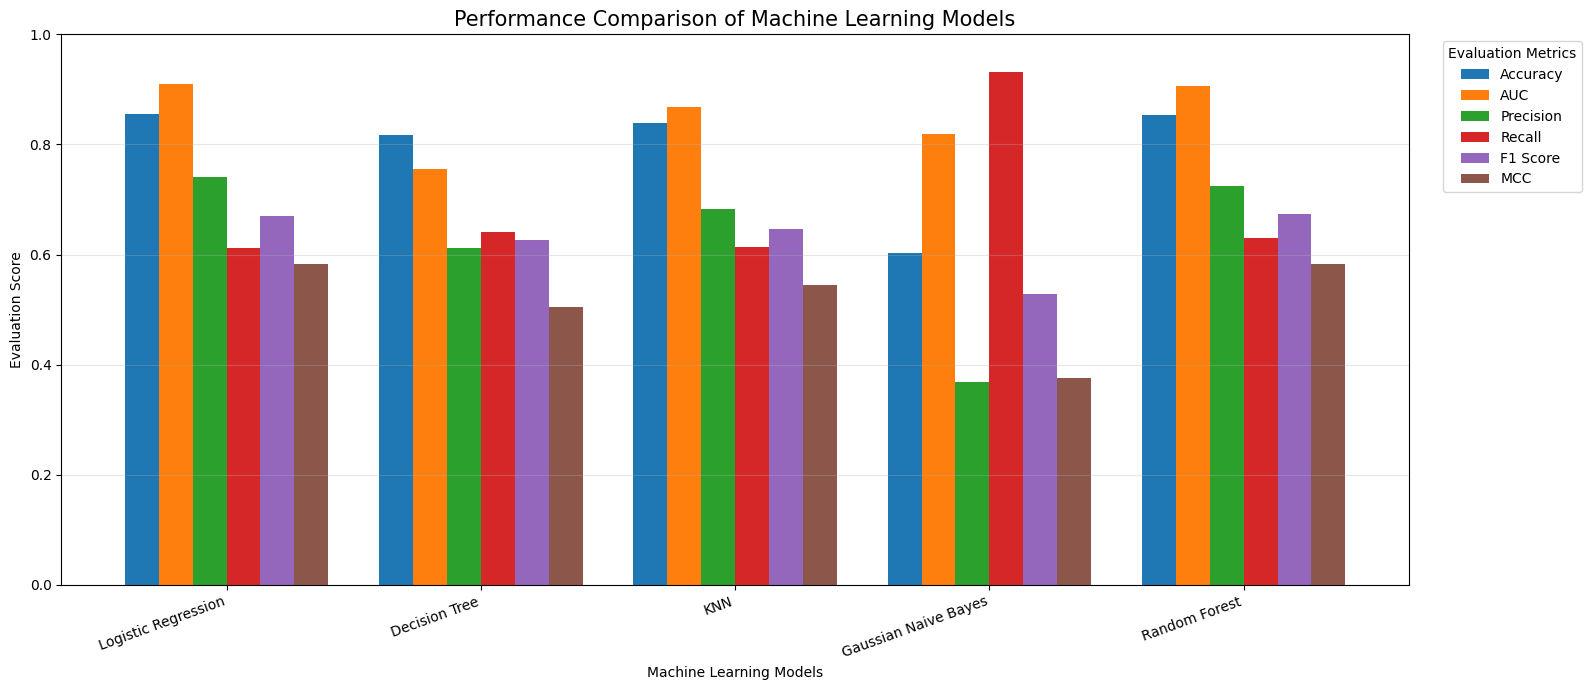

In [115]:
# Visual comparison of all evaluation metrics

metrics = [
    'Accuracy',
    'AUC',
    'Precision',
    'Recall',
    'F1 Score',
    'MCC'
]

ax = results.set_index('ML Model')[metrics].plot(
    kind='bar',
    figsize=(16, 7),
    width=0.8
)

plt.title(
    'Performance Comparison of Machine Learning Models',
    fontsize=15
)

plt.xlabel('Machine Learning Models')
plt.ylabel('Evaluation Score')

plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1)

plt.legend(
    title='Evaluation Metrics',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

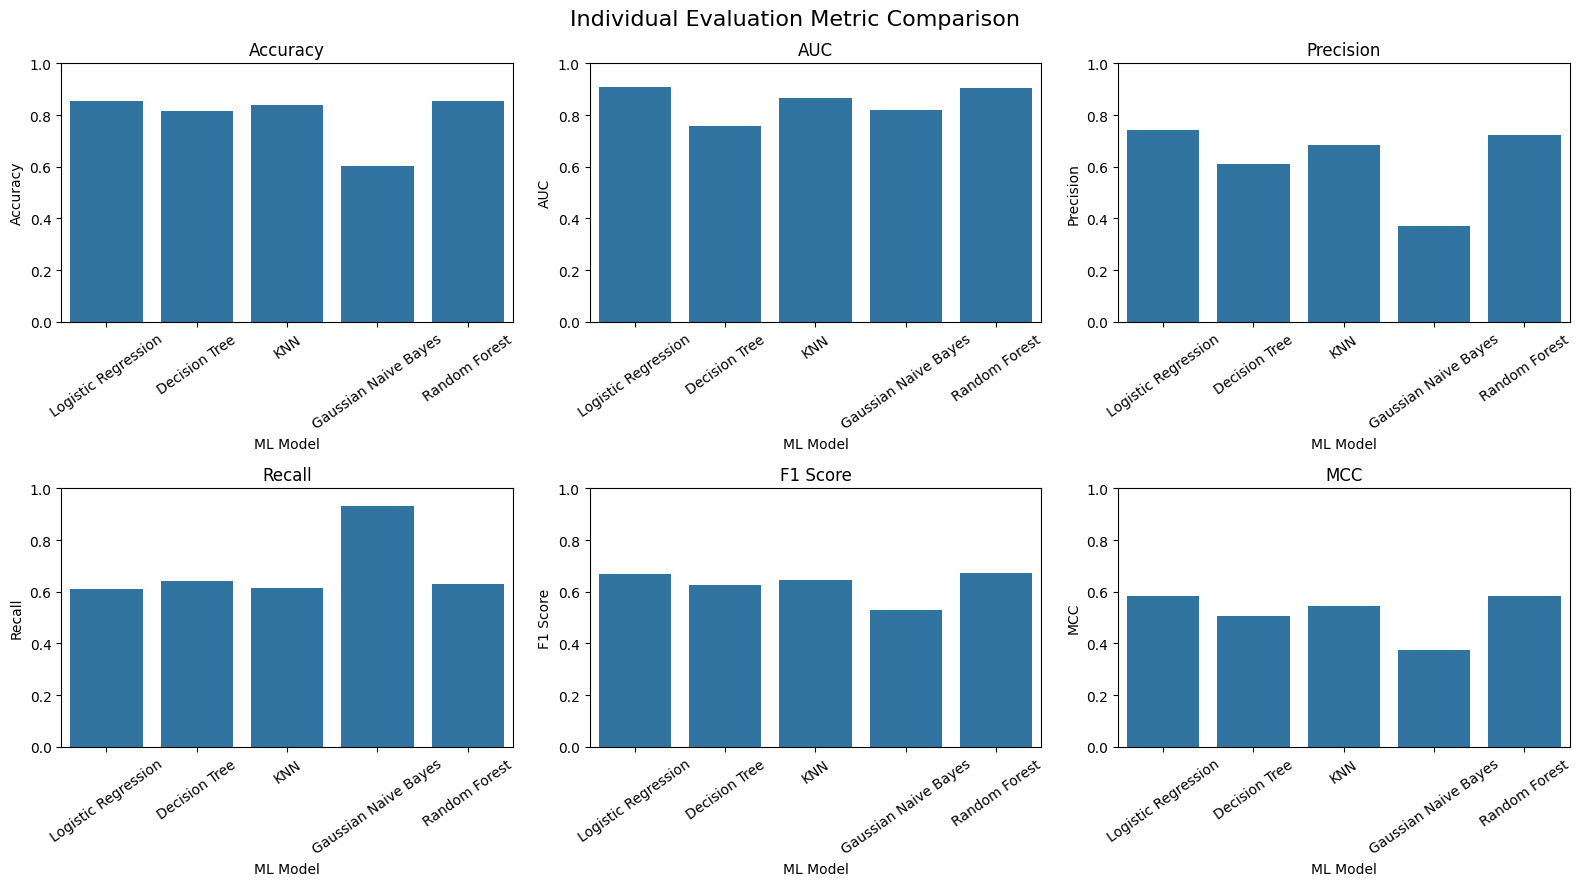

In [117]:
# Individual metric comparison

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flatten(), metrics):

    sns.barplot(
        data=results,
        x='ML Model',
        y=metric,
        ax=ax
    )

    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=35)

plt.suptitle(
    'Individual Evaluation Metric Comparison',
    fontsize=16
)

plt.tight_layout()
plt.show()

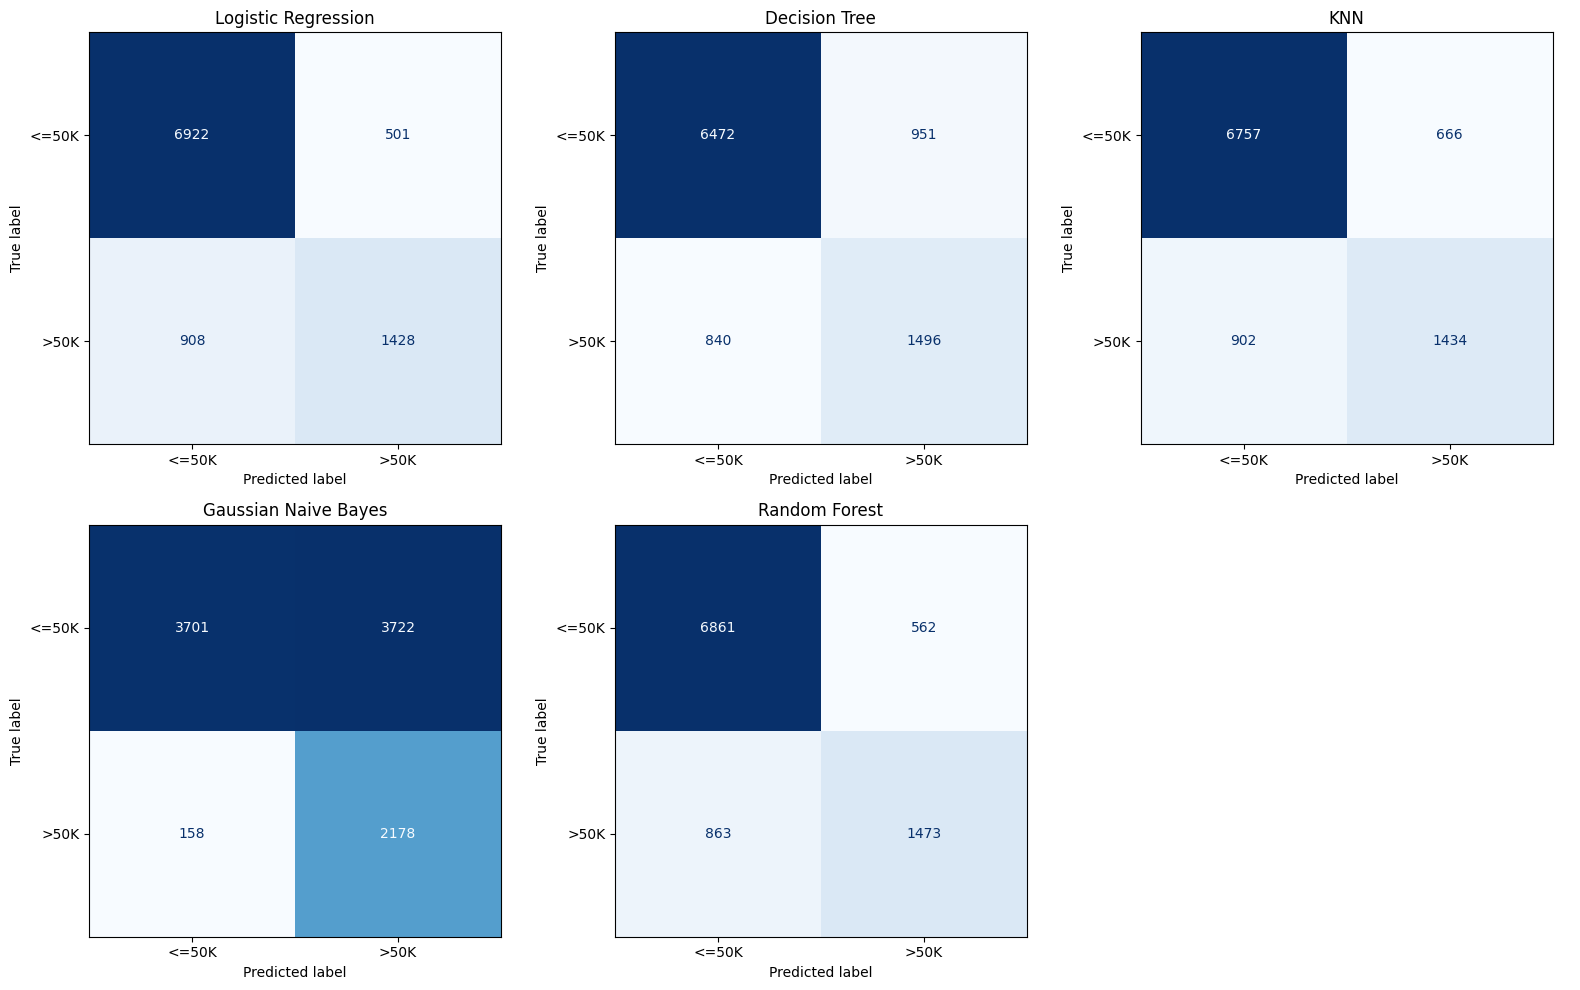

In [119]:
from sklearn.metrics import ConfusionMatrixDisplay

# Store predictions for all five models

model_predictions = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'KNN': y_pred_knn,
    'Gaussian Naive Bayes': y_pred_nb,
    'Random Forest': y_pred_rf
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, predictions) in zip(
    axes.flatten(),
    model_predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=['<=50K', '>50K'],
        cmap='Blues',
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

# Hide unused sixth plot
axes.flatten()[-1].axis('off')

plt.tight_layout()
plt.show()


### 7.3 Confusion Matrix Analysis

The confusion matrices provide a detailed comparison of correct and incorrect predictions made by the five classification models.

1. Logistic Regression demonstrated strong classification performance with 6,922 true negatives and 1,428 true positives.

2. Decision Tree correctly identified 1,496 high-income individuals but generated 951 false positive predictions.

3. KNN demonstrated reasonable classification performance with 6,757 true negatives and 1,434 true positives.

4. Gaussian Naive Bayes achieved the highest true positive count of 2,178 and the lowest false negative count of 158. However, it generated 3,722 false positives, resulting in lower precision.

5. Random Forest achieved 6,861 true negatives and 1,473 true positives, demonstrating a good balance between identifying both income categories.

Overall, Logistic Regression and Random Forest demonstrated stronger classification performance than the other models.



# 8. Overall Observations and Conclusion

Five supervised machine learning classification algorithms were implemented and evaluated using the UCI Adult Census Income dataset.

The models included Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes and Random Forest.

The evaluation was performed using Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient.

### Overall Model Comparison

Logistic Regression achieved the highest accuracy of 85.56% and AUC of 0.9101.

Random Forest achieved the highest F1 score of 0.6740 and MCC of 0.5828, demonstrating a slightly better balance between precision and recall.

Gaussian Naive Bayes achieved the highest recall of 0.9324 but had comparatively low precision.

### Overall Winner

Random Forest is selected as the overall winner based on its F1 score and MCC performance.

However, Logistic Regression also demonstrated excellent performance and achieved the highest accuracy, AUC and precision.

### Conclusion

This experiment demonstrates that different machine learning algorithms exhibit different classification characteristics on the same dataset.

The choice of the best model depends on the evaluation metric and the intended classification objective.

The experiment also highlights the importance of data preprocessing, feature encoding, feature scaling and stratified train-test splitting in developing reliable machine learning classification models.
